# SkinCare NLP Analysis – The Derma Co

**Project:** Review-Informed Skincare Product Discovery Using NLP and Data Analytics  
**Product:** 2% Sali-Cinamide Anti-Acne Face Wash (The Derma Co)

This notebook starts from the scraped CSV (`thedermaco_all_reviews.csv`) and performs:
1. Data loading and validation
2. Missing-value handling
3. Review text combination
4. Text cleaning while preserving Hinglish words
5. Identification of product-name-only reviews
6. Review-length analysis
7. Word-frequency analysis
8. Visualizations
9. Export of the preprocessed dataset

**Important:** The original scraped dataset is kept unchanged. All transformations are performed on a copy.

## 1. Import libraries

In [1]:
import re
import html
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", None)

## 2. Load the scraped reviews

Place `thedermaco_all_reviews.csv` in the same folder as this notebook. If your CSV has a different filename or location, update `INPUT_CSV`.

In [2]:
INPUT_CSV = "thedermaco_all_reviews.csv"

df = pd.read_csv(INPUT_CSV)

print("Dataset shape:", df.shape)
print("Total reviews:", len(df))
display(df.head())

Dataset shape: (162, 11)
Total reviews: 162


,review_id,product_name,reviewer_name,rating,review_title,review_text,review_date,verified_buyer,helpful_votes,not_helpful_votes,product_url
0,e18ed183-d1fb-4f47-9e5c-84e2edb3010b,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Tejas,5,Good,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2026-09-13T05:10:00Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2
1,8d555059-7343-4220-a9aa-98144cd5156e,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Kabibunisa,5,NaN,It is the super product for pimple remove,2026-08-14T02:29:15Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2
2,a4d3af1b-81db-4efd-8667-1dc49e7deb3d,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Sayma,5,Fight acne and oil control,"Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liye better h\nMuje derma ke s...",2026-08-07T05:40:16Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2
3,1c619545-cd14-477e-9c28-5abe6fc21b9b,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Athar .,5,NaN,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2026-08-02T07:12:10Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2
4,58d6f486-ec74-469e-b82b-ad8c4190fdfc,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Lucky,5,NaN,Nice,2026-02-22T05:52:29Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2


## 3. Validate the raw dataset

In [3]:
required_columns = [
    "review_id", "product_name", "reviewer_name", "rating",
    "review_title", "review_text", "review_date", "verified_buyer",
    "helpful_votes", "not_helpful_votes", "product_url"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

print("Reviews collected:", len(df))
print("Unique review IDs:", df["review_id"].nunique())
print("Duplicate review IDs:", df["review_id"].duplicated().sum())

print("\nRating distribution:")
display(df["rating"].value_counts(dropna=False).sort_index())

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

Reviews collected: 162
Unique review IDs: 162
Duplicate review IDs: 0

Rating distribution:


rating
1      4
4     26
5    132
Name: count, dtype: int64


Missing values:


,missing_values
review_id,0
product_name,0
reviewer_name,0
rating,0
review_title,9
review_text,0
review_date,0
verified_buyer,0
helpful_votes,0
not_helpful_votes,0


## 4. Create a working copy and handle missing values

Missing review titles are replaced with empty strings. Missing review text is also replaced with an empty string. Records are not deleted.

In [4]:
df_nlp = df.copy()

df_nlp["review_title"] = df_nlp["review_title"].fillna("")
df_nlp["review_text"] = df_nlp["review_text"].fillna("")

df_nlp["combined_review"] = (
    df_nlp["review_title"].astype(str) + " " +
    df_nlp["review_text"].astype(str)
).str.strip()

print("Original records:", len(df))
print("Working records:", len(df_nlp))
print("Missing combined reviews:", df_nlp["combined_review"].isna().sum())

display(df_nlp[["rating", "review_title", "review_text", "combined_review"]].head())

Original records: 162
Working records: 162
Missing combined reviews: 0


,rating,review_title,review_text,combined_review
0,5,Good,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Good 2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2)
1,5,,It is the super product for pimple remove,It is the super product for pimple remove
2,5,Fight acne and oil control,"Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liye better h\nMuje derma ke s...","Fight acne and oil control Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liy..."
3,5,,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2)
4,5,,Nice,Nice


## 5. Clean review text

The cleaning function:
- Decodes HTML entities
- Converts text to lowercase
- Removes URLs, HTML tags and email addresses
- Removes punctuation and special characters
- Keeps English letters, numbers and whitespace
- Normalizes extra spaces

Hinglish words written in the Latin alphabet (for example, `muje`, `bhot`, `pasand`) are preserved. This basic cleaning does not perform translation, stemming or stopword removal.

In [5]:
def clean_text(text):
    text = str(text)
    text = html.unescape(text)
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\\S+|www\\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove email addresses
    text = re.sub(r"\\S+@\\S+", " ", text)

    # Keep Latin letters, digits and whitespace
    text = re.sub(r"[^a-zA-Z0-9\\s]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\\s+", " ", text).strip()

    return text


df_nlp["cleaned_review"] = df_nlp["combined_review"].apply(clean_text)

display(df_nlp[["combined_review", "cleaned_review"]].head(10))

,combined_review,cleaned_review
0,Good 2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),good 2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2
1,It is the super product for pimple remove,it is the super product for pimple remove
2,"Fight acne and oil control Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liy...",fight acne and oil control yeh derma ka best facewash h isme niacinamide salicylic acid h jo acne prone skin ke liy...
3,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2
4,Nice,nice
5,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml,2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml
6,This product is super awesome. I started using this product since last 3 weeks and I already started noticing the di...,this product is super awesome i started using this product since last 3 weeks and i already started noticing the di...
7,Absolutely w... Absolutely worth it product\nI will give 9 out of 10\nI was suffering from active acne and acne mark...,absolutely w absolutely worth it product i will give 9 out of 10 i was suffering from active acne and acne marks ...
8,This anti ac... This anti acne face wash is good for treating and preventing acne ...it is gentle on skin and doesn'...,this anti ac this anti acne face wash is good for treating and preventing acne it is gentle on skin and doesn ...
9,This product... This product is great for sensitive skin and it's less foaming facewash so it's great for sensitive ...,this product this product is great for sensitive skin and it s less foaming facewash so it s great for sensitive ...


## 6. Identify product-name-only reviews

Some reviews may contain only the product name rather than customer feedback. Flag them for later analysis; do not delete them automatically.

In [6]:
def is_product_name_only(row):
    review = clean_text(row["review_text"])
    product = clean_text(row["product_name"])
    return bool(review) and review == product


df_nlp["is_product_name_only"] = df_nlp.apply(
    is_product_name_only,
    axis=1
)

print("Product-name-only reviews:", int(df_nlp["is_product_name_only"].sum()))
print("Other reviews:", int((~df_nlp["is_product_name_only"]).sum()))

display(
    df_nlp.loc[
        df_nlp["is_product_name_only"],
        ["reviewer_name", "rating", "review_text"]
    ].head(10)
)

Product-name-only reviews: 3
Other reviews: 159


,reviewer_name,rating,review_text
0,Tejas,5,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2)
3,Athar .,5,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2)
161,vishaldoi gurjar,1,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2)


## 7. Calculate review length

In [7]:
df_nlp["review_length"] = df_nlp["cleaned_review"].apply(
    lambda text: len(text.split()) if text else 0
)
df_nlp["character_count"] = df_nlp["cleaned_review"].str.len()

display(df_nlp["review_length"].describe().to_frame("word_count"))
print("Average review length:", round(df_nlp["review_length"].mean(), 2), "words")
print("Median review length:", df_nlp["review_length"].median(), "words")

,word_count
count,162.000000
mean,31.104938
std,19.131973
min,1.000000
25%,18.250000
50%,28.000000
75%,37.750000
max,102.000000


Average review length: 31.1 words
Median review length: 28.0 words


## 8. Visualize review-length distribution

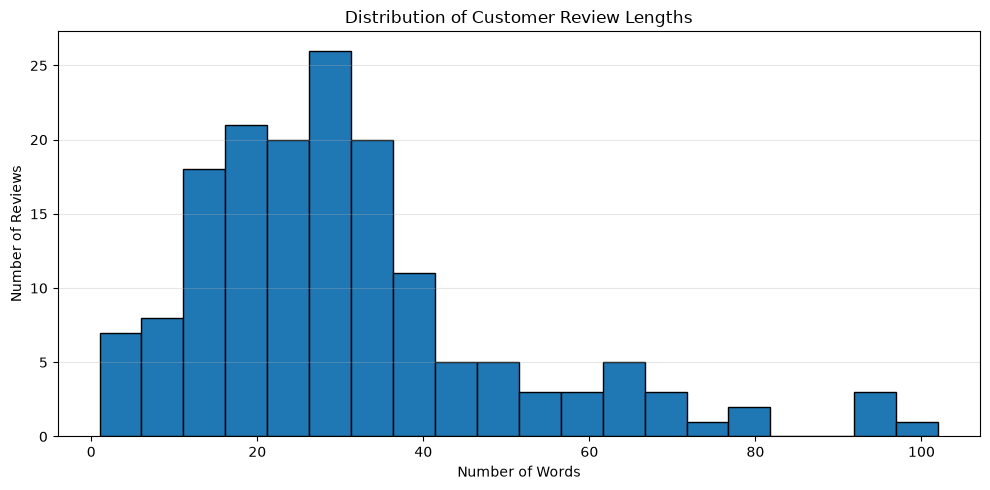

In [8]:
plt.figure(figsize=(10, 5))
plt.hist(df_nlp["review_length"], bins=20, edgecolor="black")
plt.title("Distribution of Customer Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Word-frequency analysis

This is a basic frequency count before stopword removal. Common words such as `the`, `is`, `and`, and product-related terms may rank highly. We will interpret the results carefully, especially because the dataset contains Hinglish reviews.

In [9]:
all_words = " ".join(df_nlp["cleaned_review"].fillna("")).split()
word_counts = Counter(all_words)

top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["word", "frequency"]
)

display(top_words)

,word,frequency
0,and,191
1,acne,169
2,the,160
3,i,150
4,my,143
5,skin,136
6,it,129
7,face,124
8,this,120
9,wash,110


## 10. Plot the 20 most frequent words

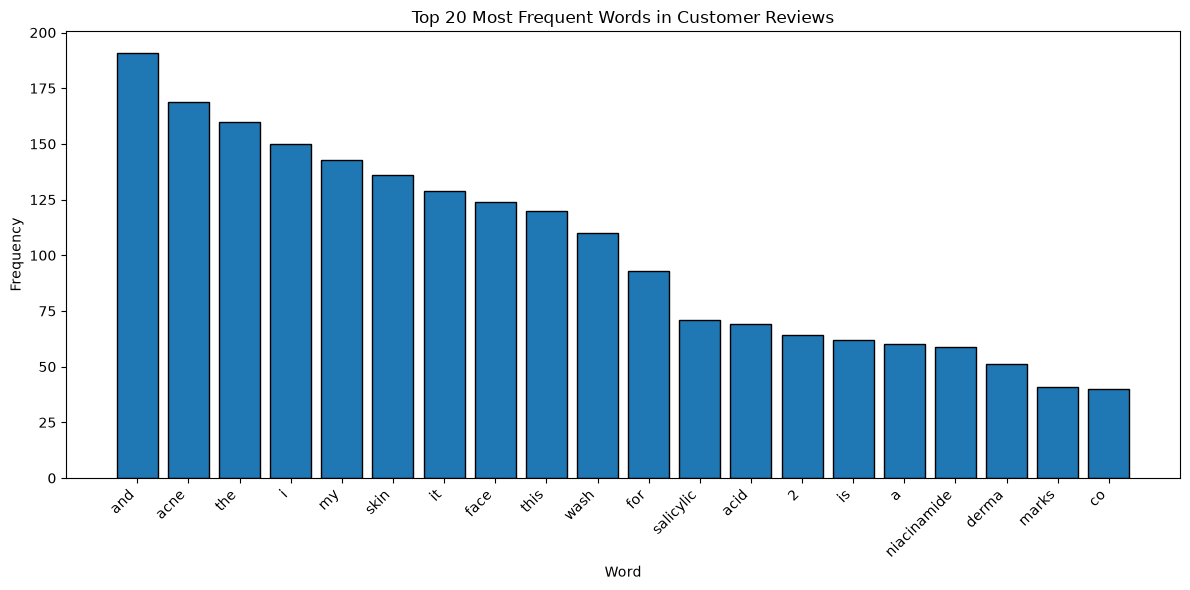

In [10]:
if not top_words.empty:
    plt.figure(figsize=(12, 6))
    plt.bar(top_words["word"], top_words["frequency"], edgecolor="black")
    plt.title("Top 20 Most Frequent Words in Customer Reviews")
    plt.xlabel("Word")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No words available for frequency analysis.")

## 11. Rating distribution visualization

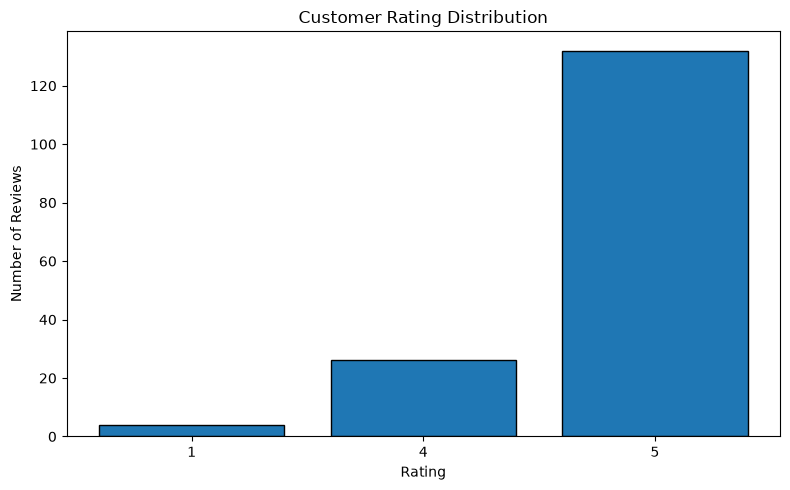

,review_count
rating,
1,4
4,26
5,132


In [11]:
rating_counts = (
    pd.to_numeric(df_nlp["rating"], errors="coerce")
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values, edgecolor="black")
plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

display(rating_counts.rename("review_count").to_frame())

## 12. Final preprocessing checks

In [12]:
print("Original records:", len(df))
print("Preprocessed records:", len(df_nlp))
print("Missing cleaned reviews:", df_nlp["cleaned_review"].isna().sum())
print("Empty cleaned reviews:", (df_nlp["cleaned_review"].str.len() == 0).sum())
print("Duplicate review IDs:", df_nlp["review_id"].duplicated().sum())

display(
    df_nlp[[
        "reviewer_name",
        "rating",
        "review_title",
        "review_text",
        "cleaned_review",
        "review_length",
        "is_product_name_only"
    ]].head(15)
)

Original records: 162
Preprocessed records: 162
Missing cleaned reviews: 0
Empty cleaned reviews: 0
Duplicate review IDs: 0


,reviewer_name,rating,review_title,review_text,cleaned_review,review_length,is_product_name_only
0,Tejas,5,Good,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),good 2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2,18,True
1,Kabibunisa,5,,It is the super product for pimple remove,it is the super product for pimple remove,8,False
2,Sayma,5,Fight acne and oil control,"Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liye better h\nMuje derma ke s...",fight acne and oil control yeh derma ka best facewash h isme niacinamide salicylic acid h jo acne prone skin ke liy...,80,False
3,Athar .,5,,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2,17,True
4,Lucky,5,,Nice,nice,1,False
5,pooja Yadav,5,,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml,2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml,14,False
6,Chaiti,5,,This product is super awesome. I started using this product since last 3 weeks and I already started noticing the di...,this product is super awesome i started using this product since last 3 weeks and i already started noticing the di...,56,False
7,PIYUSH KUMAR MEENA,5,Absolutely w...,Absolutely worth it product\nI will give 9 out of 10\nI was suffering from active acne and acne marks\nI ordered thi...,absolutely w absolutely worth it product i will give 9 out of 10 i was suffering from active acne and acne marks ...,94,False
8,Shagun Agarwal,5,This anti ac...,This anti acne face wash is good for treating and preventing acne ...it is gentle on skin and doesn't dry out skin a...,this anti ac this anti acne face wash is good for treating and preventing acne it is gentle on skin and doesn ...,66,False
9,Rujal patel,5,This product...,This product is great for sensitive skin and it's less foaming facewash so it's great for sensitive skin i would lov...,this product this product is great for sensitive skin and it s less foaming facewash so it s great for sensitive ...,68,False


## 13. Export the preprocessed dataset

The raw CSV remains unchanged. This creates a separate output file with the added preprocessing columns.

In [13]:
OUTPUT_CSV = "TheDermaCo_Preprocessed_Reviews.csv"

df_nlp.to_csv(
    OUTPUT_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Preprocessed dataset exported:", OUTPUT_CSV)
print("Rows exported:", len(df_nlp))

Preprocessed dataset exported: TheDermaCo_Preprocessed_Reviews.csv
Rows exported: 162
